# Experiment 1: LGD training dynamics

Follow optimization, predictive monitoring, parameter movement and resource use. Training-dataset partitions and outer evaluation folds are distinct.

Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.


## 0. Evidence and scope

The availability tables distinguish observed measurements from unavailable outcomes. Missing measurements are not zero effects.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, publication as pub, diagnostics as dg
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('experiment1/02_training_lgd')
report = cp.NotebookReport('Experiment 1: LGD training dynamics', sink=sink)
TRACK = 'lgd'
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.')
from src.visualize import pilots as pv
from src.visualize import dashboards as db, training_summary as ts

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Training coverage

The grid contains four bases, four peak learning rates, two anchoring settings, two adaptation modes and four dataset partitions.

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,427008,Project training diagnostics
3,Milestone rows,1536,Project trajectory diagnostics
4,Benchmark folds,8520,Project final evaluation


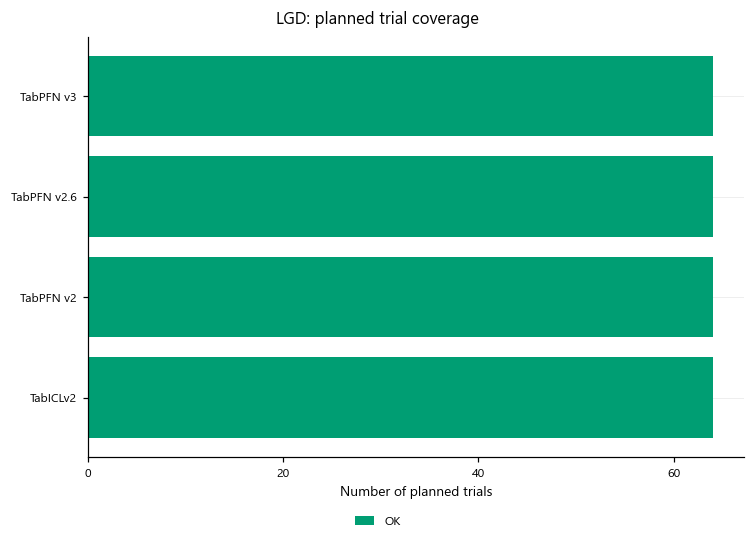

LGD. Recorded status of 256 planned LGD trials by base model. PENDING denotes no manifest outcome and can include currently running or queued jobs. INTERRUPTED denotes saved progress, not a numerical failure. This figure does not query the scheduler.

,base,learning_rate,l2sp_lambda,frozen,partition,status
0,TabPFN v2,3.000000e-07,0.000,False,0,OK
1,TabPFN v2,3.000000e-07,0.003,False,0,OK
2,TabPFN v2,3.000000e-07,0.000,True,0,OK
3,TabPFN v2,3.000000e-07,0.003,True,0,OK
4,TabPFN v2,1.000000e-06,0.000,False,0,OK
...,...,...,...,...,...,...
251,TabICLv2,1.000000e-05,0.003,True,3,OK
252,TabICLv2,3.000000e-05,0.000,False,3,OK
253,TabICLv2,3.000000e-05,0.003,False,3,OK
254,TabICLv2,3.000000e-05,0.000,True,3,OK


In [2]:
run = cp.load_campaign(1, TRACK)
report.table('Available evidence', pub.availability(run))
cp.show(sink, cp.plot_coverage(run), track=run.track)
report.table('Full configuration and partition status', run.trials[["base","learning_rate","l2sp_lambda","frozen","partition","status"]])
report.add('1. Training coverage', cp.coverage_summary(run))

## 2. Loss, optimization and predictive learning curves

Each model has a four-panel optimization dashboard. Lines average the four training-dataset partitions and then the remaining recipe settings at each learning rate. Credit and non-credit curves use AUC for PD and R² for LGD. The final five-fold benchmark is reported separately.

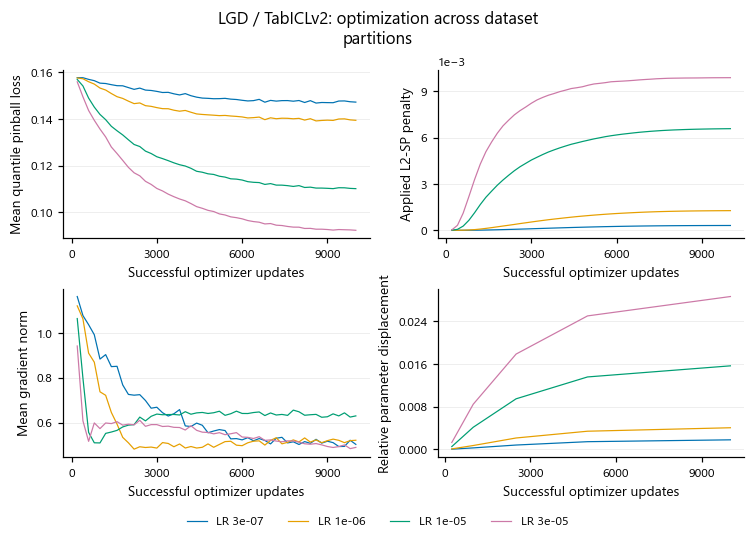

LGD. Lines give arithmetic means across all planned dataset partitions within a recipe, then equal-weight means over anchoring and adaptation settings at each peak learning rate. A missing partition or recipe produces a gap. Only the nonzero L2-SP arm enters the penalty panel. Data loss is the native query objective excluding L2-SP; incomplete table-coverage loss epochs are omitted. Epoch diagnostics use successful-update windows; parameter displacement uses exact milestones. Native losses are never averaged across model architectures.

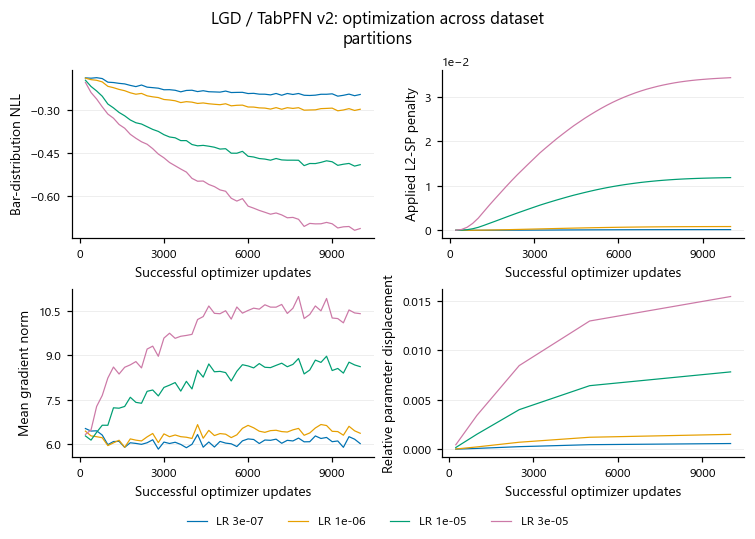

LGD. Lines give arithmetic means across all planned dataset partitions within a recipe, then equal-weight means over anchoring and adaptation settings at each peak learning rate. A missing partition or recipe produces a gap. Only the nonzero L2-SP arm enters the penalty panel. Data loss is the native query objective excluding L2-SP; incomplete table-coverage loss epochs are omitted. Epoch diagnostics use successful-update windows; parameter displacement uses exact milestones. Native losses are never averaged across model architectures.

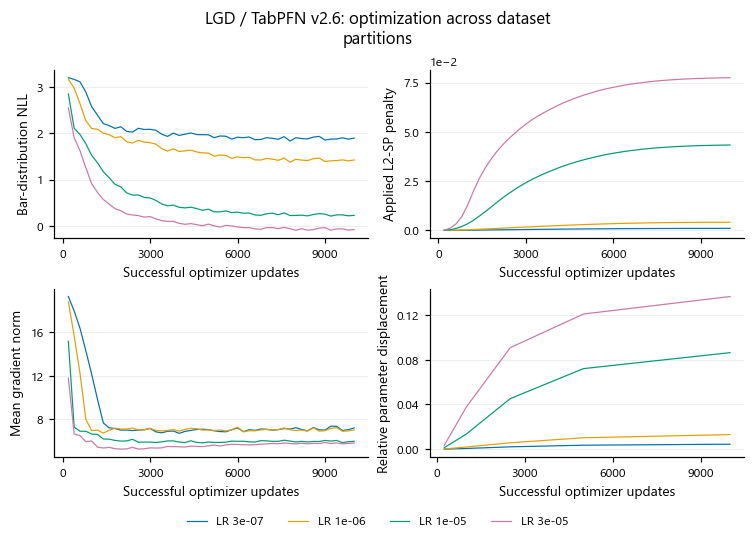

LGD. Lines give arithmetic means across all planned dataset partitions within a recipe, then equal-weight means over anchoring and adaptation settings at each peak learning rate. A missing partition or recipe produces a gap. Only the nonzero L2-SP arm enters the penalty panel. Data loss is the native query objective excluding L2-SP; incomplete table-coverage loss epochs are omitted. Epoch diagnostics use successful-update windows; parameter displacement uses exact milestones. Native losses are never averaged across model architectures.

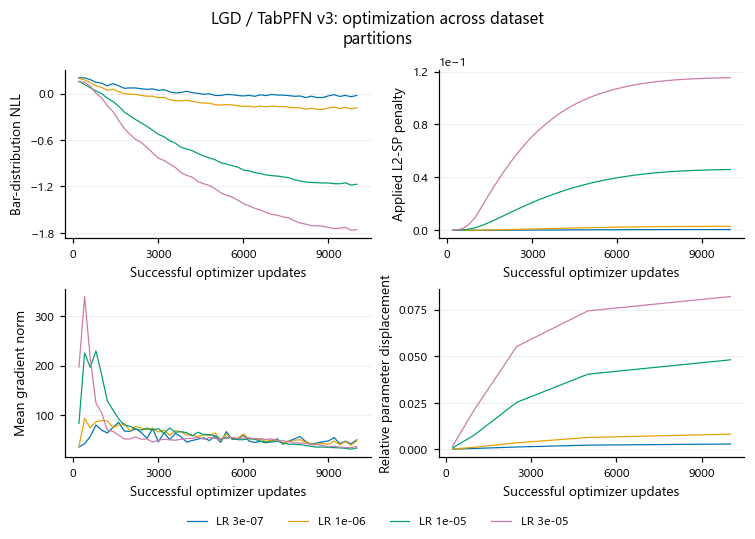

LGD. Lines give arithmetic means across all planned dataset partitions within a recipe, then equal-weight means over anchoring and adaptation settings at each peak learning rate. A missing partition or recipe produces a gap. Only the nonzero L2-SP arm enters the penalty panel. Data loss is the native query objective excluding L2-SP; incomplete table-coverage loss epochs are omitted. Epoch diagnostics use successful-update windows; parameter displacement uses exact milestones. Native losses are never averaged across model architectures.

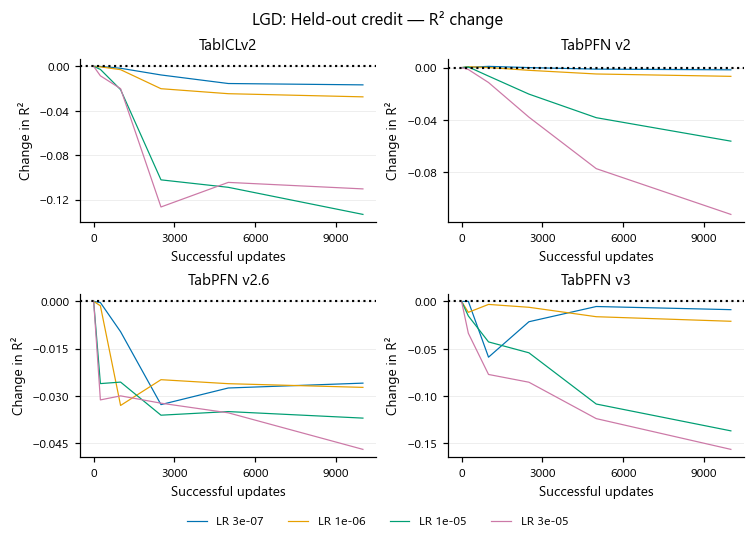

LGD. Each recipe first pairs each table's score with its update-zero value, averages repeated partitions within table, and gives tables equal weight. Lines then average remaining recipe settings at a peak learning rate or sampling protocol. The complete planned partition cohort and unchanged baseline table support are required at every milestone. Missing observations remain gaps. Positive changes indicate improvement. These fixed-context monitors are separate from five-fold evaluation.

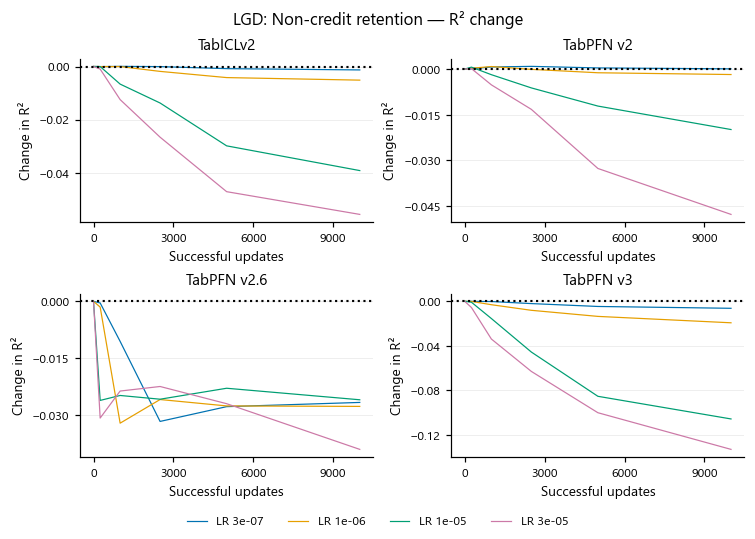

LGD. Each recipe first pairs each table's score with its update-zero value, averages repeated partitions within table, and gives tables equal weight. Lines then average remaining recipe settings at a peak learning rate or sampling protocol. The complete planned partition cohort and unchanged baseline table support are required at every milestone. Missing observations remain gaps. Positive changes indicate improvement. These fixed-context monitors are separate from five-fold evaluation.

,base,learning_rate,l2sp_lambda,frozen,sampling,partition,seed,epochs,nonfinite_diagnostics,peak_epoch_gradient,peak_epoch_clipped_fraction,peak_l2sp_penalty,amp_skips,data_skips,peak_weight_drift
0,TabPFN v2,3.000000e-07,0.000,False,one_sample,0,42,1667,0,24.376100,1.000000,0.000000,0,0,0.000802
1,TabPFN v2,3.000000e-07,0.003,False,one_sample,0,42,1667,0,19.063607,1.000000,0.000240,0,0,0.000655
2,TabPFN v2,3.000000e-07,0.000,True,one_sample,0,42,1667,0,7.304855,1.000000,0.000000,0,0,0.000557
3,TabPFN v2,3.000000e-07,0.003,True,one_sample,0,42,1667,0,7.301828,0.833333,0.000033,0,0,0.000259
4,TabPFN v2,1.000000e-06,0.000,False,one_sample,0,42,1667,0,25.082857,1.000000,0.000000,0,0,0.002030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,TabICLv2,1.000000e-05,0.003,True,one_sample,3,42,1667,0,4.625928,0.500000,0.002968,0,0,0.010721
252,TabICLv2,3.000000e-05,0.000,False,one_sample,3,42,1667,0,2.083212,0.333333,0.000000,0,0,0.039761
253,TabICLv2,3.000000e-05,0.003,False,one_sample,3,42,1667,0,2.698303,0.500000,0.010073,0,0,0.005835
254,TabICLv2,3.000000e-05,0.000,True,one_sample,3,42,1667,0,2.839929,0.500000,0.000000,0,0,0.050410


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,recorded_epochs,full_coverage_epochs,fullest_observed_tables,min_observed_tables,last_update,partial_coverage_epochs
0,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-05,0.000,False,one_sample,1667,1666,6,4,10000,1
1,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-05,0.003,False,one_sample,1667,1666,6,4,10000,1
2,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-05,0.003,True,one_sample,1667,1666,6,4,10000,1
3,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-05,0.000,True,one_sample,1667,1666,6,4,10000,1
4,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-06,0.000,False,one_sample,1667,1666,6,4,10000,1
...,...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,3.000000e-05,0.000,True,one_sample,1667,1666,6,4,10000,1
252,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,3.000000e-07,0.000,False,one_sample,1667,1666,6,4,10000,1
253,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,3.000000e-07,0.003,False,one_sample,1667,1666,6,4,10000,1
254,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,3.000000e-07,0.003,True,one_sample,1667,1666,6,4,10000,1


,trial_name,successful_updates,train_loss,observed_tables,full_observed_tables,complete_pass,base,learning_rate,l2sp_lambda,frozen,sampling
0,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,10000,0.078071,4,6,False,TabICLv2,1.000000e-05,0.003,False,one_sample
1,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,10000,0.101507,4,6,False,TabICLv2,1.000000e-05,0.003,True,one_sample
2,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,10000,0.060607,4,6,False,TabICLv2,1.000000e-05,0.000,False,one_sample
3,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,10000,0.096523,4,6,False,TabICLv2,1.000000e-05,0.000,True,one_sample
4,cpt_main_v5_s00_lgd_tabicl-regressor-v2-202602...,10000,0.114678,4,6,False,TabICLv2,1.000000e-06,0.003,False,one_sample
...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,10000,-0.668074,4,6,False,TabPFN v3,3.000000e-05,0.000,True,one_sample
252,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,10000,-0.167231,4,6,False,TabPFN v3,3.000000e-07,0.003,False,one_sample
253,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,10000,0.121446,4,6,False,TabPFN v3,3.000000e-07,0.003,True,one_sample
254,cpt_main_v5_s03_lgd_tabpfn-v3-regressor-v3_def...,10000,-0.163359,4,6,False,TabPFN v3,3.000000e-07,0.000,False,one_sample


In [3]:
cp.show(sink, db.plot_optimization(run), track=run.track)
cp.show(sink, db.plot_monitor_curves(run), track=run.track)
cp.show(sink, db.plot_monitor_curves(run, 'ood'), track=run.track)
report.table('Numerical health, including exact-zero events', pv.health_table(run))
for label, frame in cp.loss_coverage_tables(run).items():
    report.table(label, frame)
report.add('2. Loss, optimization and predictive learning curves', 'Data loss excludes anchoring: PD query cross-entropy; TabPFN LGD bar-distribution NLL; TabICLv2 LGD mean quantile pinball loss. Equal partition and configuration weights apply to optimization curves; monitoring first gives each table equal weight. Native objective scales remain separate by architecture. Missing support produces gaps.')

## 3. What training choices changed in the held-out monitors

One matrix summarizes each choice at the final fixed-context monitoring milestone, separately for held-out credit and non-credit tables. Changing anchoring, peak learning rate or backbone freezing holds the dataset partition, seed and every other setting fixed. Section 2 retains learning trajectories; the complete paired loss, gradient, penalty and displacement curves remain in the text summary.

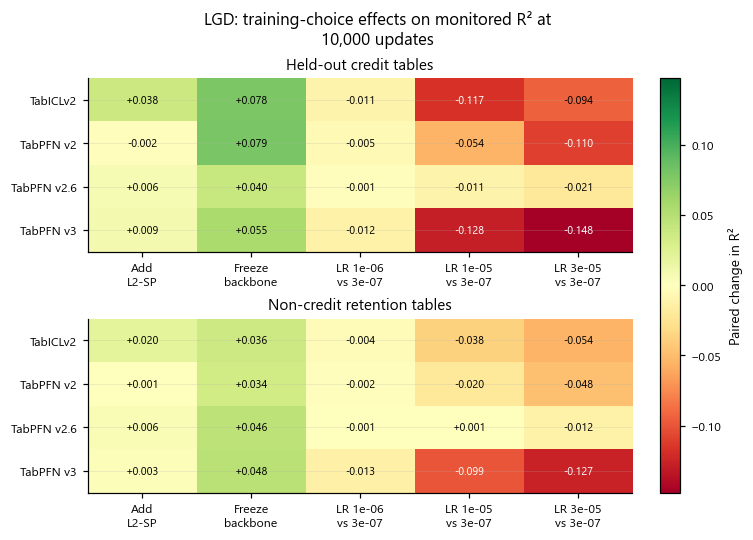

LGD. Fixed-context monitor differences at 10,000 successful updates. Each cell compares a changed training choice with its matched reference: L2-SP 0.003 versus 0, transformer-backbone freezing versus all-parameter updates, or the stated peak learning rate versus 3e-7. Positive values favor the changed choice. Each pair fixes base model, training partition, seed and every other recipe setting. Within the displayed metric and domain, all planned pairs and their unchanged update-zero table support are required; repeated recipes and partitions are averaged within table before the equal-table mean. Models remain separate. Counts and full paired monitor trajectories accompany the values. Observed support: credit: TabICLv2 8 tables, TabPFN v2 8 tables, TabPFN v2.6 8 tables, TabPFN v3 8 tables; retention: TabICLv2 4 tables, TabPFN v2 4 tables, TabPFN v2.6 4 tables, TabPFN v3 4 tables. Native loss and optimizer contrasts are retained as tables. These held-out monitoring contexts are separate from the five-fold final benchmark; no recipe is selected here.

In [4]:
cp.show(sink, ts.plot_choices(run), track=run.track)
report.add('3. What training choices changed in the held-out monitors', 'Differences compare matched choices at 10,000 successful updates. References are no L2-SP, all-parameter updates and LR 3e-7. Positive monitor differences favor the changed choice; every other configuration setting is held fixed before equal-table averaging. Each base remains separate. These fixed-context scores do not replace the final five-fold benchmark. Native-scale optimization contrasts remain in the complete tables.')

## 4. Applied learning-rate schedule

The schedule spans the full successful-update budget. A segmented job resumes the same schedule.

In [5]:
report.table('Schedule settings', run.trials[['learning_rate','l2sp_lambda','frozen']].drop_duplicates())
report.add('4. Applied learning-rate schedule', 'PD and LGD use the same configured schedule, shown once in the PD training notebook. Initialization has zero rate; log axes only show positive rates.')

,learning_rate,l2sp_lambda,frozen
0,3.000000e-07,0.000,False
1,3.000000e-07,0.003,False
2,3.000000e-07,0.000,True
3,3.000000e-07,0.003,True
4,1.000000e-06,0.000,False
5,1.000000e-06,0.003,False
6,1.000000e-06,0.000,True
7,1.000000e-06,0.003,True
8,1.000000e-05,0.000,False
9,1.000000e-05,0.003,False


## 5. Parameter movement

Whole-model displacement and tensor-level movement are complementary summaries of adaptation. One figure compares all models; color identifies the model and line style identifies which parameters were updated. Complete planned trial support is required at each milestone.

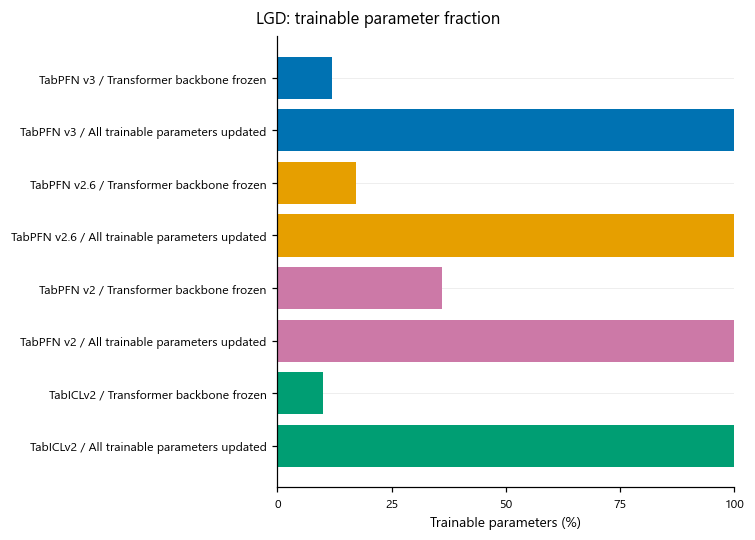

LGD. Trainable parameters divided by total model parameters for each base and adaptation mode. Counts are taken from observed trial provenance; median counts are used where recipes repeat a model. The frozen condition leaves family-specific surrounding modules trainable; it is not the same parameter subset across architectures.

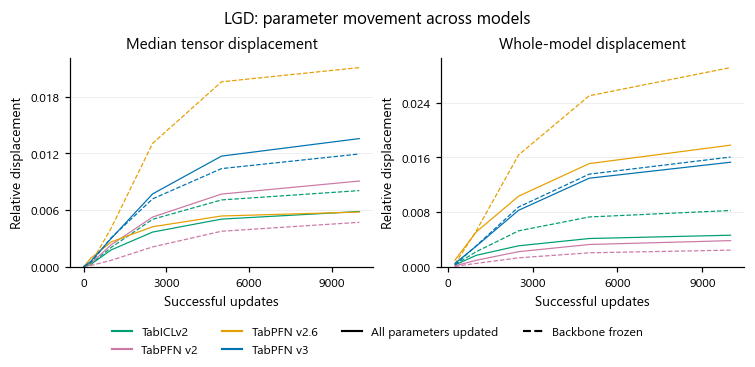

LGD. Training seed: 42. Parameter displacement at recorded milestones, shown together by model and update scope. Whole-model displacement is norm weighted; the tensor panel first takes the median across anchored tensors within a trial. Lines then take the median over the planned recipes and partitions within a model and scope. A milestone with an incomplete trial cohort remains a gap. Line color identifies the model and line style the update scope. The numerical values use different parameter sets across architectures and are descriptive movement diagnostics, not predictive-quality or causal comparisons.

In [6]:
cp.show(sink, pub.plot_trainable_fraction(run), track=run.track)
cp.show(sink, ts.plot_movement(run), track=run.track)
report.add('5. Parameter movement', 'Anchored displacement depends on the trainable subset. Freezing leaves family-specific surrounding modules trainable; movement is not evidence of causal predictive improvement.')

## 6. Resources, cost and scope

A compact cost figure compares recorded training time and peak allocated tensor memory across models and update scopes. Device utilization and power remain in tables; total device capacity is not plotted as an experimental effect.

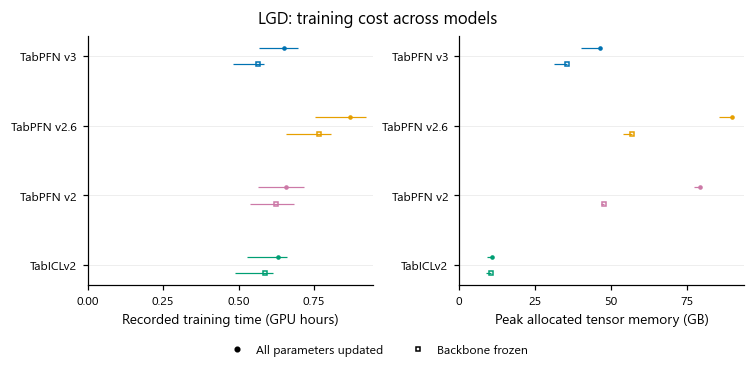

LGD. Training seed: 42. Completed-trial training cost by model and update scope. Points show medians and horizontal intervals show interquartile ranges across observed recipes and training partitions, not confidence intervals. Each trial contributes once. Counts and all trial measurements accompany the plot. Time is recorded training wall time, excluding queue wait; memory is the process's recorded peak allocated tensor memory, rather than total device capacity or device-wide use. Recipe pooling is descriptive and does not establish an equal-compute predictive comparison. Missing or unfinished measurements are not zeros.

,base,frozen,gpu_utilization_percent_median,power_watts_median,device_memory_used_mib_median,trials
0,TabICLv2,False,96.0,527.3500,11640.0,32
1,TabICLv2,True,97.0,563.9500,11464.0,32
2,TabPFN v2,False,98.0,722.1100,77267.0,32
3,TabPFN v2,True,98.0,717.0950,47128.0,32
4,TabPFN v2.6,False,97.0,671.4400,86836.0,32
5,TabPFN v2.6,True,98.0,701.5375,56518.0,32
6,TabPFN v3,False,88.0,519.2900,46444.0,32
7,TabPFN v3,True,93.0,370.7300,35743.0,32


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,seed,partition,min_train_rows,track,...,evidence_status,base_short,lr_tag,training_seconds,compute_seconds,data_wait_seconds,amp_skipped_steps,data_skipped_steps,compute_fraction,data_wait_fraction
0,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.000,False,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2144.159500,2034.655456,109.504044,0,0,0.948929,0.051071
1,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.003,False,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2202.615980,2094.815415,107.800565,0,0,0.951058,0.048942
2,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.000,True,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2067.195755,1958.897112,108.298643,0,0,0.947611,0.052389
3,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.003,True,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2076.249450,1966.739212,109.510237,0,0,0.947256,0.052744
4,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,1.000000e-06,0.000,False,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,1e-06,2159.031472,2051.618729,107.412743,0,0,0.950250,0.049750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-05,0.003,True,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,1e-05,2275.730247,2162.357915,113.372332,0,0,0.950182,0.049818
252,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.000,False,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,3e-05,2632.817777,2235.119499,397.698279,0,0,0.848946,0.151054
253,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.003,False,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,3e-05,3018.019105,2377.990581,640.028524,0,0,0.787931,0.212069
254,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.000,True,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,3e-05,2925.888253,2116.013288,809.874965,0,0,0.723204,0.276796


,"('elapsed_sec', 'count')","('elapsed_sec', 'median')","('elapsed_sec', 'min')","('elapsed_sec', 'max')","('sec_per_step', 'count')","('sec_per_step', 'median')","('sec_per_step', 'min')","('sec_per_step', 'max')","('peak_gpu_gb', 'count')","('peak_gpu_gb', 'median')",...,"('rows_seen', 'min')","('rows_seen', 'max')","('trainable_params', 'count')","('trainable_params', 'median')","('trainable_params', 'min')","('trainable_params', 'max')","('final_drift', 'count')","('final_drift', 'median')","('final_drift', 'min')","('final_drift', 'max')"
"('TabICLv2', False)",32,2276.071883,961.560047,3470.316446,32,0.227607,0.096156,0.347032,32,10.993,...,24755261,92356996,32,28544983.0,28544983,28544983,32,0.004610,0.001245,0.039761
"('TabICLv2', True)",32,2119.043170,867.936296,3391.145004,32,0.211904,0.086794,0.339115,32,10.582,...,24755261,92356996,32,2823127.0,2823127,2823127,32,0.008231,0.001635,0.055758
"('TabPFN v2', False)",32,2361.717630,1538.051174,2822.926711,32,0.236172,0.153805,0.282293,32,79.359,...,24755261,55679662,32,11081864.0,11081864,11081864,32,0.003816,0.000655,0.018744
"('TabPFN v2', True)",32,2240.936746,1466.558088,2688.054035,32,0.224094,0.146656,0.268805,32,47.736,...,24755261,55679662,32,4003976.0,4003976,4003976,32,0.002423,0.000259,0.033726
"('TabPFN v2.6', False)",32,3126.751230,1846.503835,3650.390853,32,0.312675,0.184650,0.365039,32,89.881,...,24755261,59013662,32,12854792.0,12854792,12854792,32,0.017804,0.003871,0.147133
"('TabPFN v2.6', True)",32,2757.451636,1535.985452,3148.595242,32,0.275745,0.153599,0.314860,32,56.925,...,24755261,59013662,32,2224136.0,2224136,2224136,32,0.029176,0.002876,0.353532
"('TabPFN v3', False)",32,2341.062530,1332.112761,3017.463288,32,0.234106,0.133211,0.301746,32,46.569,...,24755261,92356996,32,58274936.0,58274936,58274936,32,0.015303,0.002324,0.094542
"('TabPFN v3', True)",32,2029.083655,1133.990570,2403.997635,32,0.202908,0.113399,0.240400,32,35.573,...,24755261,92356996,32,6917240.0,6917240,6917240,32,0.016063,0.002040,0.191601


In [7]:
cp.show(sink, ts.plot_resources(run), track=run.track)
report.table('Sampled device-counter summaries', pv.resource_summary(run))
report.table('Trial costs and numerical diagnostics', cp.diagnostics(run))
report.table('Completed-trial cost distribution', pub.cost_summary(run))
report.add('6. Resources, cost and scope', dg.summary(run) + '\nDevice samples are not integrated energy or billed allocation time. The main grid has one training seed; table and partition variation does not estimate seed robustness.')

## Complete text summary

All displayed values, support counts, tables and captions in section order.

In [8]:
print(report.summary(sink))

Experiment 1: LGD training dynamics

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.

1. Training coverage
Run cpt_main_v5; LGD; 256 planned trials; target 10,000 successful updates.
status
OK    256
1536 trajectory records; 8520 benchmark fold records.
PENDING means no recorded outcome; it can include running or queued work. This is not live scheduler state.

Table: Available evidence
CSV (first column: row index)
row,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,427008,Project training diagnostics
3,Milestone rows,1536,Project trajectory diagnostics
4,B